## Projeto Sprint 11 — Análise do Comportamento dos Usuários e Teste A/A/B

Objetivo: analisar o funil de conversão de um aplicativo de vendas de alimentos e avaliar, por meio de um teste A/A/B, se a alteração das fontes influencia o comportamento dos usuários.

## LEGENDA DE DADOS:
Datasets: '/datasets/logs_exp_us.csv'
*EventName-* Nome do evento 

*UserID-* Identificador de usuário exclusivo 

*EventTime-* Hora do evento 

*Group-* Numero do experimento:
246 e 247 grupos de controle 
248 grupo teste

In [1]:
import pandas as pd 
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

In [2]:

#carregando o df
logs = pd.read_csv('/datasets/logs_exp_us.csv', sep='\t')
print(logs.head(10))


                 EventName         DeviceIDHash  EventTimestamp  ExpId
0         MainScreenAppear  4575588528974610257      1564029816    246
1         MainScreenAppear  7416695313311560658      1564053102    246
2  PaymentScreenSuccessful  3518123091307005509      1564054127    248
3         CartScreenAppear  3518123091307005509      1564054127    248
4  PaymentScreenSuccessful  6217807653094995999      1564055322    248
5         CartScreenAppear  6217807653094995999      1564055323    248
6       OffersScreenAppear  8351860793733343758      1564066242    246
7         MainScreenAppear  5682100281902512875      1564085677    246
8         MainScreenAppear  1850981295691852772      1564086702    247
9         MainScreenAppear  5407636962369102641      1564112112    246


In [3]:
# Renomeando as colunas
logs = logs.rename(columns={
    'DeviceIDHash': 'UserID',
    'EventTimestamp': 'EventTime',
    'ExpId':'Group'})

In [4]:
 #analisando as informações das colunas 
logs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   EventName  244126 non-null  object
 1   UserID     244126 non-null  int64 
 2   EventTime  244126 non-null  int64 
 3   Group      244126 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 7.5+ MB


In [5]:
#transformando a coluna EventTime em data time 
logs['EventTime'] = pd.to_datetime(
    logs['EventTime'],
    unit='s'
)
logs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   EventName  244126 non-null  object        
 1   UserID     244126 non-null  int64         
 2   EventTime  244126 non-null  datetime64[ns]
 3   Group      244126 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 7.5+ MB


In [6]:
#separando uma coluna só para data e só para hora
logs['EventData'] = logs['EventTime'].dt.date
logs['EventTime'] = logs['EventTime'].dt.time
logs.head()

,EventName,UserID,EventTime,Group,EventData
0,MainScreenAppear,4575588528974610257,04:43:36,246,2019-07-25
1,MainScreenAppear,7416695313311560658,11:11:42,246,2019-07-25
2,PaymentScreenSuccessful,3518123091307005509,11:28:47,248,2019-07-25
3,CartScreenAppear,3518123091307005509,11:28:47,248,2019-07-25
4,PaymentScreenSuccessful,6217807653094995999,11:48:42,248,2019-07-25


In [7]:
#analisando numeros duplicados 
print(logs.isna().sum())

print(logs.duplicated().sum())



EventName    0
UserID       0
EventTime    0
Group        0
EventData    0
dtype: int64
413


In [8]:
#analisando as colunas duplicadas 
logs[logs.duplicated(keep=False)].head(20)

,EventName,UserID,EventTime,Group,EventData
452,MainScreenAppear,5613408041324010552,08:19:44,248,2019-07-30
453,MainScreenAppear,5613408041324010552,08:19:44,248,2019-07-30
2348,CartScreenAppear,1694940645335807244,21:51:39,248,2019-07-31
2350,CartScreenAppear,1694940645335807244,21:51:39,248,2019-07-31
3572,MainScreenAppear,434103746454591587,02:59:37,248,2019-08-01
3573,MainScreenAppear,434103746454591587,02:59:37,248,2019-08-01
4075,MainScreenAppear,3761373764179762633,03:47:46,247,2019-08-01
4076,MainScreenAppear,3761373764179762633,03:47:46,247,2019-08-01
4801,MainScreenAppear,2835328739789306622,04:44:01,248,2019-08-01
4803,MainScreenAppear,2835328739789306622,04:44:01,248,2019-08-01


In [9]:
#removendo os numeros duplicados 
logs = logs.drop_duplicates()
logs.duplicated().sum()

0


### Conclusão da limpeza dos dados

Durante a preparação dos dados, renomeamos as colunas para facilitar a leitura e a análise. A coluna `DeviceIDHash` foi renomeada para `UserID`, `EventTimestamp` para `EventTime` e `ExpId` para `Group`, que representa os grupos experimentais.

Em seguida, convertemos os registros de tempo para o formato datetime e separamos as informações em duas colunas: `EventTime`, contendo apenas as horas, os minutos e os segundos, e `EventData`, contendo somente as datas dos eventos.

Ao investigar a qualidade dos dados, identificamos **413 registros duplicados**, que apresentavam informações idênticas em todas as colunas. Optamos por remover esses registros para evitar possíveis distorções na contagem de eventos e nos resultados da análise.

Após a remoção, realizamos uma nova verificação e confirmamos que **não restaram registros duplicados no conjunto de dados**.

Com essa etapa concluída, os dados estão preparados para iniciarmos a análise exploratória, na qual investigaremos a quantidade de eventos, os usuários únicos e o período de observação do aplicativo.


# CONTANDO OS NUMEROS DE EVENTOS E USUÁRIOS QUE FICAM NOS REGISTROS E O NUMERO MÉDIO DE EVENTOS POR USUÁRIOS


In [10]:
#quantos eventos ficam nos registros 
EventTotal = len(logs['EventName'])
print(EventTotal)

243713


In [11]:
#quantos usuários ficam nos registros 
UserTotal = logs['UserID'].nunique()
print(UserTotal)

7551


In [12]:
#numero medio de eventos por usuários 
EventMedia = EventTotal / UserTotal
print(round(EventMedia,2))


32.28


### Conclusão — Análise geral dos dados

Após a limpeza dos dados, identificamos um total de **243.713 eventos registrados**, realizados por **7.551 usuários únicos**.

A média foi de **32,28 eventos por usuário**, indicando a quantidade média de interações realizadas por cada usuário durante o período analisado.

# Descobrindo a Data maxima e minima dos eventos e o periodo que os dados começam a ser completos.

In [13]:
Eventmax = logs['EventData'].max()
print(f'Data do último evento: {Eventmax}')

Data do último evento: 2019-08-07


In [14]:
EventMin= logs['EventData'].min()
print(f'Data do primeiro evento: {EventMin}')

Data do primeiro evento: 2019-07-25


In [15]:
#Descobrindo o valor de eventos por dia 
EventsPerDay= logs['EventData'].value_counts()
EventsPerDay.sort_index()

2019-07-25        9
2019-07-26       31
2019-07-27       55
2019-07-28      105
2019-07-29      184
2019-07-30      412
2019-07-31     2030
2019-08-01    36141
2019-08-02    35554
2019-08-03    33282
2019-08-04    32968
2019-08-05    36058
2019-08-06    35788
2019-08-07    31096
Name: EventData, dtype: int64

In [16]:
#analisando os eventos do dia 31
Events31 = logs[
    logs['EventData'] == pd.to_datetime('2019-07-31').date()
]
#procurando o primeiro evento do dia 
PrimeiroEvento31 = Events31['EventTime'].min()
print(f'Primeiro evento do dia 31: {PrimeiroEvento31}')

UltimoEvento31 = UltimoEvento31 = Events31['EventTime'].max()
print(f'Último evento do dia 31: {UltimoEvento31}')

Primeiro evento do dia 31: 01:11:46
Último evento do dia 31: 23:59:59


In [17]:
print(Events31['EventTime'].dtype)

object


In [18]:
#analisando os eventos por hora do dia 31
Events31 = logs[
    logs['EventData'] == pd.to_datetime('2019-07-31').date()
].copy()
Events31['EventHour'] = Events31['EventTime'].apply(
    lambda x: x.hour
)
#contando os eventos por horas em ordem crescente
Events31['EventHour'].value_counts().sort_index()

1       3
2       2
3      12
4      22
5      27
6      31
7      45
8      31
9      49
10     88
11     53
12     82
13     92
14     97
15    111
16    108
17    113
18    106
19     65
20     56
21    424
22    309
23    104
Name: EventHour, dtype: int64

In [19]:
#analisando os eventos por hora do dia 01
Events01 = logs[
    logs['EventData'] == pd.to_datetime('2019-08-01').date()
].copy()
Events01['EventHour'] = Events01['EventTime'].apply(
    lambda x: x.hour
)
#contando os eventos por horas em ordem crescente
Events01['EventHour'].value_counts().sort_index()

0      192
1      228
2      328
3      657
4      837
5     1114
6     1432
7     1756
8     1901
9     2004
10    1962
11    2539
12    2556
13    2289
14    2806
15    2347
16    2632
17    2428
18    2100
19    1813
20    1009
21     673
22     293
23     245
Name: EventHour, dtype: int64

In [20]:
#criando a coluna para o histograma 
logs['EventDataTime'] = pd.to_datetime(
    logs['EventData'].astype(str) + ' ' + logs['EventTime'].astype(str)
)
logs['EventDataTime'].dtype

dtype('<M8[ns]')

In [21]:
#separando o evento por hora
EventosPorHora = logs['EventDataTime'].dt.floor('h').value_counts().sort_index()
print(EventosPorHora.sum())

243713


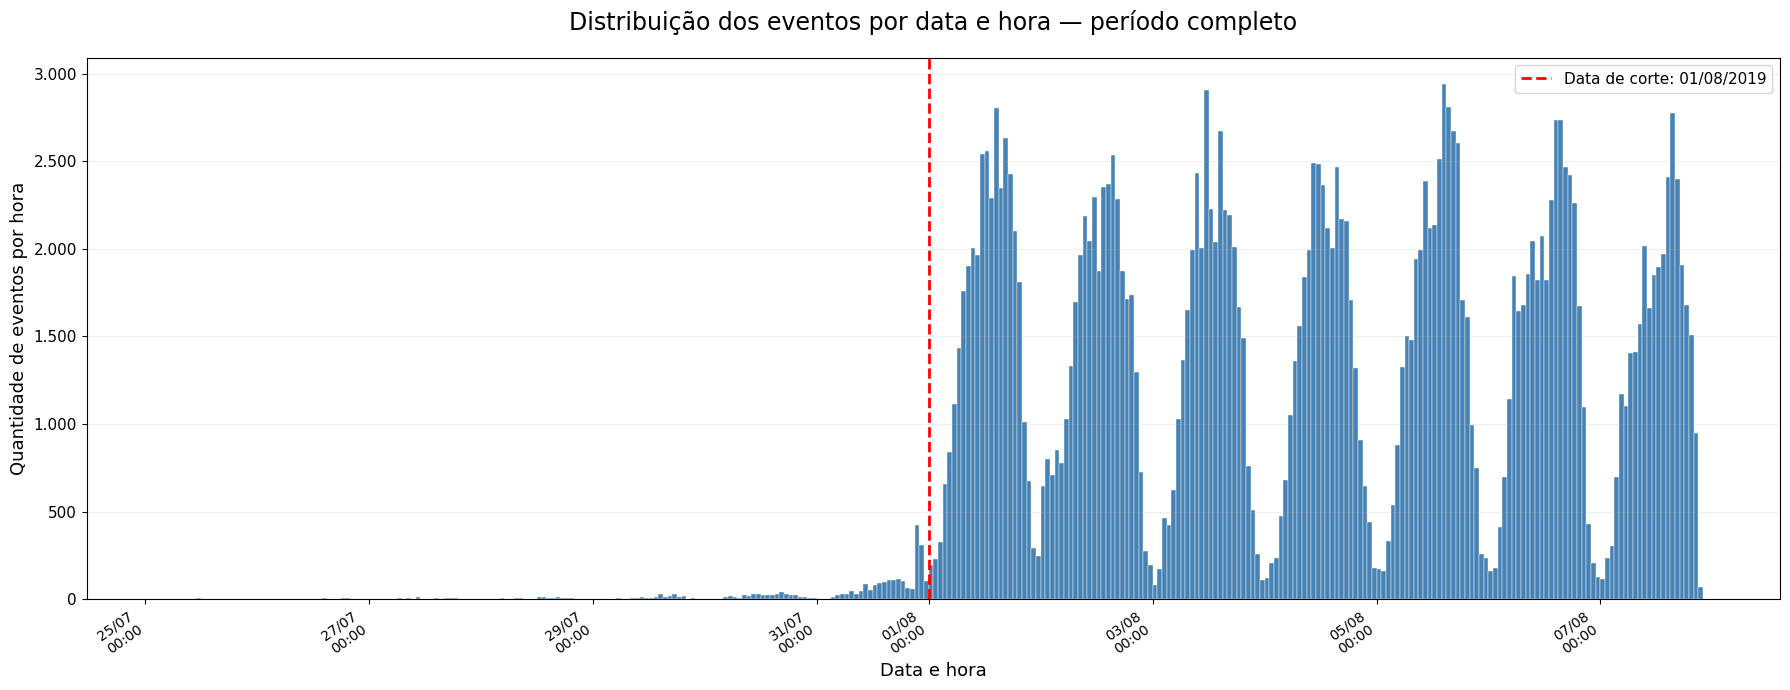

In [22]:
# Utilizando todos os registros, sem filtragem
dados = logs['EventDataTime'].dropna()

# Criando intervalos de uma hora
inicio = dados.min().floor('h')
fim = dados.max().ceil('h')

intervalos = pd.date_range(
    start=inicio,
    end=fim,
    freq='h'
)

# Convertendo datas para o formato do Matplotlib
datas = mdates.date2num(dados.dt.to_pydatetime())
bins = mdates.date2num(intervalos.to_pydatetime())

# Data de corte: 01/08/2019
data_corte = mdates.date2num(
    pd.Timestamp('2019-08-01 00:00').to_pydatetime()
)

# Criando o histograma
fig, ax = plt.subplots(figsize=(18, 7))

ax.hist(
    datas,
    bins=bins,
    color='steelblue',
    edgecolor='white',
    linewidth=0.3
)

# Linha vertical indicando a data de corte
ax.axvline(
    data_corte,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Data de corte: 01/08/2019'
)

# Formatação do eixo X
localizador = mdates.AutoDateLocator(
    minticks=6,
    maxticks=10
)

ax.xaxis.set_major_locator(localizador)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%d/%m\n%H:%M')
)

# Separadores de milhar no eixo Y
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f'{x:,.0f}'.replace(',', '.')
    )
)

# Títulos e identificação dos eixos
ax.set_title(
    'Distribuição dos eventos por data e hora — período completo',
    fontsize=17,
    pad=20
)

ax.set_xlabel('Data e hora', fontsize=13)
ax.set_ylabel('Quantidade de eventos por hora', fontsize=13)

ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.2)

plt.xticks(rotation=35, ha='right', fontsize=10)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

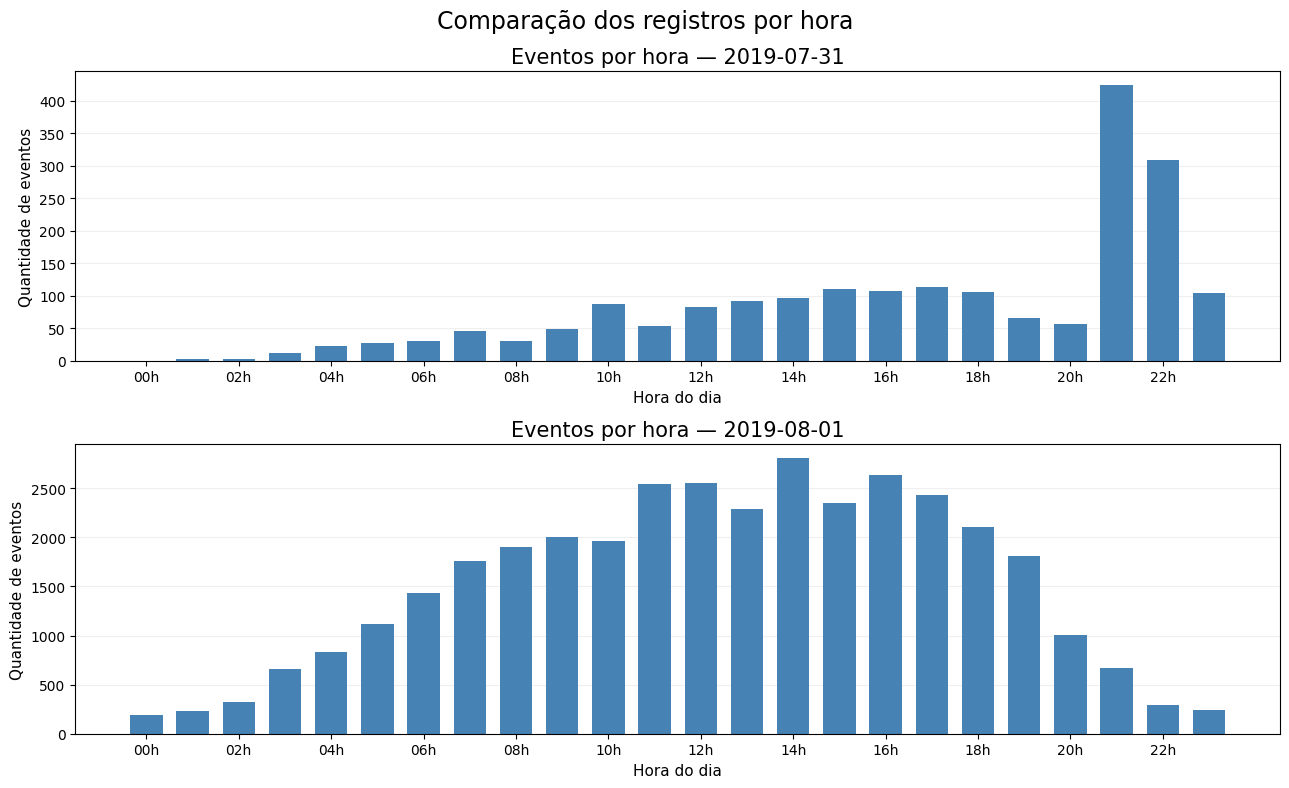

In [23]:
#gráfico por um periodo teste 
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

dias = ['2019-07-31', '2019-08-01']

for ax, dia in zip(axes, dias):

    horas = pd.date_range(dia, periods=24, freq='h')

    eventos = EventosPorHora.reindex(horas, fill_value=0)

    ax.bar(
        range(24),
        eventos.values,
        color='steelblue',
        width=0.7
    )

    ax.set_title(f'Eventos por hora — {dia}', fontsize=15)
    ax.set_ylabel('Quantidade de eventos', fontsize=11)
    ax.set_xlabel('Hora do dia', fontsize=11)

    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels([f'{h:02d}h' for h in range(0, 24, 2)])

    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle('Comparação dos registros por hora', fontsize=17)
plt.tight_layout()
plt.show()


### Conclusão — Definição do período confiável da análise

Ao analisar a distribuição dos eventos por data, identificamos uma quantidade muito baixa de registros nos primeiros dias do conjunto de dados.

Entre 25 e 30 de julho, a quantidade de eventos aumentou gradualmente, passando de apenas 9 registros em 25 de julho para 412 em 30 de julho. No dia 31 de julho, foram registrados 2.030 eventos, número ainda muito inferior aos dias seguintes.

Para investigar essa diferença, analisamos a distribuição dos eventos por hora do dia 31 de julho. Identificamos registros entre 01h e 23h, porém com uma distribuição bastante irregular e volumes muito baixos em diversos horários. Também observamos que não houve registros na primeira hora do dia.

Em seguida, comparamos esses resultados com o dia 1º de agosto, que apresentou 36.141 eventos, distribuídos pelas 24 horas do dia. Nos dias seguintes, a quantidade de registros permaneceu relativamente estável, variando entre aproximadamente 31 mil e 36 mil eventos diários.

Com base nessas evidências, identificamos fortes indícios de que os registros anteriores a 1º de agosto estavam incompletos, possivelmente por questões técnicas de coleta.

Por esse motivo, definimos **1 a 7 de agosto de 2019, uma semana de dados estáveis**, optando por desconsiderar os registros anteriores para evitar que dados potencialmente incompletos distorçam os resultados do funil de conversão e do teste A/A/B.

ros anteriores para evitar que dados potencialmente incompletos distorçam os resultados do funil de conversão e do teste A/A/B.

# Verificando a perca de eventos depois da filtragem

In [24]:
#filtrando o dataframe pelo periodo escolhido
logs_filtrados = logs[
    logs['EventData'] >= pd.to_datetime('2019-08-01').date()
].copy()

In [25]:
#analisando se a filtragem deu certo 
logs_filtrados['EventData'].min()

datetime.date(2019, 8, 1)

In [26]:
#filtrando o numeros de eventos
EventosFiltrados = len(logs_filtrados)
print(f'Numero de eventos filtrados:', EventosFiltrados)
# numeros de eventos excluidos
EventosExcluidos = len(logs) - EventosFiltrados
print(f'Eventos Excluidos após a filtragem:', EventosExcluidos)

Numero de eventos filtrados: 240887
Eventos Excluidos após a filtragem: 2826


In [27]:
# % de perda de eventos 
PerdaDeEventos = EventosExcluidos / len(logs) * 100
print(f' Porcentagem da perda dos eventos depois da filtragem:', PerdaDeEventos)

 Porcentagem da perda dos eventos depois da filtragem: 1.159560630741897


In [28]:
#quantidade de usuários unicos antes da filtragem e depois da filtragem 
UsuariosAntes = logs['UserID'].nunique()
print(f'Usuarios unicos antes da filtragem:', UsuariosAntes)
UsuariosDepois = logs_filtrados['UserID'].nunique()
print(f'Usuarios unicos depois da filtragem:', UsuariosDepois)

Usuarios unicos antes da filtragem: 7551
Usuarios unicos depois da filtragem: 7534


In [29]:
#chegando a perda de usuarios por porcentagem
PerdaDeUsuarios = (UsuariosAntes - UsuariosDepois) / UsuariosAntes * 100

print(f'Porcentagem de usuários perdidos: {PerdaDeUsuarios:.2f}%')

Porcentagem de usuários perdidos: 0.23%


### Conclusão — Impacto da filtragem dos dados

Após analisarmos os gráficos e identificarmos indícios de registros incompletos antes de 1º de agosto de 2019, decidimos excluir os dados anteriores a essa data.

Com a filtragem, tivemos uma perda de **2.826 eventos**, representando **1,16% do total original**.

A perda de usuários únicos foi ainda menor: apenas **17 usuários**, correspondentes a **0,23% do total inicial**.

Portanto, concluímos que a filtragem resultou em uma perda relativamente pequena de dados, preservando a maior parte dos eventos e usuários para as próximas etapas da análise.

# Certificando que existem os 3 grupos experimentais após a filtragem 


In [30]:
#agrupando e fazendo a contagem de usuários de cada grupo 
GroupTotal = logs_filtrados.groupby('Group')['UserID'].nunique()
print(GroupTotal)

Group
246    2484
247    2513
248    2537
Name: UserID, dtype: int64


In [31]:
#verificando se os usuários de cada grupo são unicos
GruposPorUsuario = logs_filtrados.groupby('UserID')['Group'].nunique()
print(GruposPorUsuario)

GruposPorUsuario.value_counts().sort_index()

UserID
6888746892508752       1
6909561520679493       1
6922444491712477       1
7435777799948366       1
7702139951469979       1
                      ..
9217594193087726423    1
9219463515465815368    1
9220879493065341500    1
9221926045299980007    1
9222603179720523844    1
Name: Group, Length: 7534, dtype: int64


1    7534
Name: Group, dtype: int64

# Analisando Eventos diários e a frequencia de ocorrência deles

In [32]:
#contando eventos que ocorreram 
FrequenciaEventos = logs_filtrados['EventName'].value_counts()
print(FrequenciaEventos)

MainScreenAppear           117328
OffersScreenAppear          46333
CartScreenAppear            42303
PaymentScreenSuccessful     33918
Tutorial                     1005
Name: EventName, dtype: int64


In [33]:
#verificando os usuários unicos nos eventos 
ResumoEventos = logs_filtrados.groupby('EventName').agg(
         TotalEventos=('UserID', 'size'),
          UsuarioUnicos=('UserID', 'nunique')
)
print(ResumoEventos)

                         TotalEventos  UsuarioUnicos
EventName                                           
CartScreenAppear                42303           3734
MainScreenAppear               117328           7419
OffersScreenAppear              46333           4593
PaymentScreenSuccessful         33918           3539
Tutorial                         1005            840


### Conclusão — Frequência dos eventos

A tela principal apresentou o maior volume de interações, com **117.328 eventos realizados por 7.419 usuários únicos**. Já o pagamento bem-sucedido registrou **33.918 eventos realizados por 3.539 usuários únicos**.

Observamos uma redução significativa no número de usuários entre esses eventos, o que indica a necessidade de investigar as etapas intermediárias do funil para identificar onde ocorrem as maiores perdas.

In [34]:
# Numero de usuários que executaram cada página 
ResumoEventos['ProporcaoUsuarios'] = round(
    ResumoEventos['UsuarioUnicos'] / UsuariosDepois * 100, 2
)

print(ResumoEventos)

                         TotalEventos  UsuarioUnicos  ProporcaoUsuarios
EventName                                                              
CartScreenAppear                42303           3734              49.56
MainScreenAppear               117328           7419              98.47
OffersScreenAppear              46333           4593              60.96
PaymentScreenSuccessful         33918           3539              46.97
Tutorial                         1005            840              11.15


In [35]:
ResumoEventos = ResumoEventos.sort_values(
    by='UsuarioUnicos',
    ascending=False
)

display(ResumoEventos)

,TotalEventos,UsuarioUnicos,ProporcaoUsuarios
EventName,,,
MainScreenAppear,117328,7419,98.47
OffersScreenAppear,46333,4593,60.96
CartScreenAppear,42303,3734,49.56
PaymentScreenSuccessful,33918,3539,46.97
Tutorial,1005,840,11.15


In [36]:
#localizando usuários unicos da pagina de ofertas
UsuariosOfertas = ResumoEventos.loc['OffersScreenAppear', 'UsuarioUnicos']

#localizando usuários unicos da página principal
UsuariosPrincipal = ResumoEventos.loc['MainScreenAppear', 'UsuarioUnicos']

#conversão de usuários da pagina de oferta para principal
ConversaoOfertas = UsuariosOfertas / UsuariosPrincipal * 100

print(f'Proporção de usuários nas ofertas: {ConversaoOfertas:.2f}%')

Proporção de usuários nas ofertas: 61.91%


In [37]:
#proporção carrinho para oferta 
UsuariosCarrinhos = ResumoEventos.loc['CartScreenAppear', 'UsuarioUnicos']

ConversaoCarrinho = UsuariosCarrinhos / UsuariosOfertas * 100

print(f'Proporção de usuários no carrinho: {ConversaoCarrinho:.2f}%')

Proporção de usuários no carrinho: 81.30%


In [38]:
#conversão pagamento 
UsuariosPagamento = ResumoEventos.loc[
    'PaymentScreenSuccessful',
    'UsuarioUnicos'
]


ConversaoPagamento = UsuariosPagamento / UsuariosCarrinhos * 100

print(f'Proporção no pagamento: {ConversaoPagamento:.2f}%')

Proporção no pagamento: 94.78%


# Porcentagem de perda de usuários a cada etapa

In [39]:
#porcentagem de usuário que deixaram a cada etapa 
etapas = [
    'MainScreenAppear',
    'OffersScreenAppear',
    'CartScreenAppear',
    'PaymentScreenSuccessful'
]

usuarios_funil = ResumoEventos.loc[etapas, 'UsuarioUnicos']

for i in range(len(usuarios_funil) - 1):

    anterior = usuarios_funil.iloc[i]
    seguinte = usuarios_funil.iloc[i + 1]

    diferenca = anterior - seguinte

    perda_percentual = diferenca / anterior * 100

    print(f'Diferença: {diferenca} usuários')
    print(f'Perda percentual: {perda_percentual:.2f}%')

Diferença: 2826 usuários
Perda percentual: 38.09%
Diferença: 859 usuários
Perda percentual: 18.70%
Diferença: 195 usuários
Perda percentual: 5.22%


# Porcentagem de usuários que fazem o caminho inteiro desde o primeiro evento até o pagamento

In [40]:
# Porcentagem de usuários que fazem o caminho inteiro até o pagamento
ConversaoTotal = UsuariosPagamento / UsuariosPrincipal * 100

print(f'Conversão total: {ConversaoTotal:.2f}%')

Conversão total: 47.70%


### Conclusão — Análise do Funil de Eventos

Organizamos os eventos na seguinte sequência: `MainScreenAppear → OffersScreenAppear → CartScreenAppear → PaymentScreenSuccessful`.

Desconsideramos o evento `Tutorial`, pois ele não representa uma etapa obrigatória para finalizar uma compra. Calculamos o funil utilizando a quantidade de usuários únicos em cada etapa, sem exigir a confirmação da sequência cronológica dos eventos.

Identificamos que a quantidade de usuários com pagamentos bem-sucedidos corresponde a **47,70% dos usuários que visualizaram a tela principal**.

A maior redução ocorreu entre a tela principal e a tela de ofertas, com **38,09%**, enquanto a menor foi entre o carrinho e o pagamento, com **5,22%**.

Esses resultados sugerem que a etapa de ofertas merece uma investigação mais aprofundada para identificar possíveis oportunidades de melhoria. Também observamos que o número de usuários com pagamentos bem-sucedidos é próximo ao número de usuários que visualizaram o carrinho.

# 

Diferença estatistica significativa entre as amostragens 246 e 247

<b>Teste A/A — Grupos 246 e 247</b>

<b>H₀ — Hipótese nula:</b> não existe diferença entre as proporções dos grupos.

<b>H₁ — Hipótese alternativa:</b> existe diferença entre as proporções dos grupos.

In [41]:

EventoPrincipal = logs_filtrados[
    logs_filtrados['EventName'] == 'MainScreenAppear'
]

UsuariosPorGrupo = EventoPrincipal.groupby('Group')['UserID'].nunique()

print(UsuariosPorGrupo)

Group
246    2450
247    2476
248    2493
Name: UserID, dtype: int64


In [42]:

#porcentagem por grupo 
ProporcaoGrupos = UsuariosPorGrupo / GroupTotal * 100
print(round(ProporcaoGrupos, 2))


Group
246    98.63
247    98.53
248    98.27
Name: UserID, dtype: float64


# TESTE A/A 

In [43]:
# Usuários que realizaram o evento
count = [
    UsuariosPorGrupo.loc[246],
    UsuariosPorGrupo.loc[247]
]

# Total de usuários em cada grupo
nobs = [
    GroupTotal.loc[246],
    GroupTotal.loc[247]
]

In [44]:
# Teste A/A — Grupos 246 e 247
alpha = 0.05

z_stat, p_value = proportions_ztest(
    count=count,
    nobs=nobs
)

print(f'Estatística Z: {z_stat:.4f}')
print(f'Valor-p: {p_value:.4f}')

if p_value < alpha:
    print('Rejeitamos H₀: existe diferença estatisticamente significativa.')
else:
    print('Não rejeitamos H₀: não encontramos diferença estatisticamente significativa.')

Estatística Z: 0.3093
Valor-p: 0.7571
Não rejeitamos H₀: não encontramos diferença estatisticamente significativa.


In [45]:

# função de repetição de eventos 
def teste_aa(evento):

    dados_evento = logs_filtrados[
        logs_filtrados['EventName'] == evento
    ]

    usuarios_por_grupo = dados_evento.groupby('Group')['UserID'].nunique()

    count = usuarios_por_grupo.loc[[246, 247]].values

    nobs = GroupTotal.loc[[246, 247]].values

    z_stat, p_value = proportions_ztest(
        count=count,
        nobs=nobs
    )

    return p_value

#testando a função 
teste_aa('MainScreenAppear')


0.7570597232046099

In [46]:
#repetindo a função para todos os eventos 
#filtrando os eventos 
Eventos = logs_filtrados['EventName'].unique()
#usando o método for para automatizar todos os eventos 
for evento in Eventos:

    p_value = teste_aa(evento)

    print(f'{evento}: valor-p = {p_value:.4f}')

Tutorial: valor-p = 0.9377
MainScreenAppear: valor-p = 0.7571
OffersScreenAppear: valor-p = 0.2481
CartScreenAppear: valor-p = 0.2288
PaymentScreenSuccessful: valor-p = 0.1146


### Conclusão — Teste A/A

Ao comparar os grupos de controle 246 e 247 nos cinco eventos,
todos os valores-p foram superiores ao nível de significância
de 0,05.

Dessa forma, não rejeitamos a hipótese nula em nenhum dos
testes, pois não encontramos diferenças estatisticamente
significativas entre as proporções dos grupos.

Os resultados são favoráveis à consistência da divisão
experimental, permitindo prosseguir com a análise do grupo
de teste.

# Teste A/B grupo 246

In [47]:
#função para o teste A/B
# função de repetição de eventos 
def teste_ab(evento):

    dados_evento = logs_filtrados[
        logs_filtrados['EventName'] == evento
    ]

    usuarios_por_grupo = dados_evento.groupby('Group')['UserID'].nunique()

    count = usuarios_por_grupo.loc[[246, 248]].values

    nobs = GroupTotal.loc[[246, 248]].values

    z_stat, p_value = proportions_ztest(
        count=count,
        nobs=nobs
    )

    return p_value

#teste da função 
teste_ab('MainScreenAppear')

0.2949721933554553

In [48]:
#automatizando a função para todos os eventos for evento in Eventos:

for evento in Eventos:

    p_value = teste_ab(evento)

    print(f'{evento}: valor-p = {p_value:.4f}')

    if p_value < 0.05:
        print('Rejeitamos H0')
    else:
        print('Não rejeitamos H0')

Tutorial: valor-p = 0.8264
Não rejeitamos H0
MainScreenAppear: valor-p = 0.2950
Não rejeitamos H0
OffersScreenAppear: valor-p = 0.2084
Não rejeitamos H0
CartScreenAppear: valor-p = 0.0784
Não rejeitamos H0
PaymentScreenSuccessful: valor-p = 0.2123
Não rejeitamos H0


# Teste A/B grupo 247

In [49]:

#teste ab grupo2
def teste_ab2(evento):

    dados_evento = logs_filtrados[
        logs_filtrados['EventName'] == evento
    ]

    usuarios_por_grupo = dados_evento.groupby('Group')['UserID'].nunique()

    count = usuarios_por_grupo.loc[[247, 248]].values

    nobs = GroupTotal.loc[[247, 248]].values

    z_stat, p_value = proportions_ztest(
        count=count,
        nobs=nobs
    )

    return p_value

#função para os 5 testes 
for evento in Eventos:

    p_value = teste_ab2(evento)

    print(f'{evento}: valor-p = {p_value:.4f}')

    if p_value < alpha:
        print('Rejeitamos H0')
    else:
        print('Não rejeitamos H0')


Tutorial: valor-p = 0.7653
Não rejeitamos H0
MainScreenAppear: valor-p = 0.4587
Não rejeitamos H0
OffersScreenAppear: valor-p = 0.9198
Não rejeitamos H0
CartScreenAppear: valor-p = 0.5786
Não rejeitamos H0
PaymentScreenSuccessful: valor-p = 0.7373
Não rejeitamos H0


# Teste A/B grupo grupo combinado


In [50]:
# Teste A/B — Controle combinado x Experimental

def teste_ab_combinado(evento):

    dados_evento = logs_filtrados[
        logs_filtrados['EventName'] == evento
    ]

    usuarios_por_grupo = dados_evento.groupby('Group')['UserID'].nunique()

    count = [
        usuarios_por_grupo.loc[[246, 247]].sum(),
        usuarios_por_grupo.loc[248]
    ]

    nobs = [
        GroupTotal.loc[[246, 247]].sum(),
        GroupTotal.loc[248]
    ]

    z_stat, p_value = proportions_ztest(
        count=count,
        nobs=nobs
    )

    return p_value

#função 5 testes 
for evento in Eventos:

    p_value = teste_ab_combinado(evento)

    print(f'{evento}: valor-p = {p_value:.4f}')

    if p_value < alpha:
        print('Rejeitamos H0')
    else:
        print('Não rejeitamos H0')

Tutorial: valor-p = 0.7649
Não rejeitamos H0
MainScreenAppear: valor-p = 0.2942
Não rejeitamos H0
OffersScreenAppear: valor-p = 0.4343
Não rejeitamos H0
CartScreenAppear: valor-p = 0.1818
Não rejeitamos H0
PaymentScreenSuccessful: valor-p = 0.6004
Não rejeitamos H0


In [51]:
# Nível de significância e múltiplas comparações

alpha = 0.05

TotalTestes = 20

alpha_ajustado = alpha / TotalTestes

print(f'Total de testes realizados: {TotalTestes}')
print(f'Nível de significância original: {alpha}')
print(f'Nível de significância ajustado: {alpha_ajustado:.4f}')

Total de testes realizados: 20
Nível de significância original: 0.05
Nível de significância ajustado: 0.0025


### Conclusão — Testes A/B

Após realizar as comparações entre os grupos de controle
e o grupo experimental, incluindo a combinação dos grupos
246 e 247, todos os valores-p foram superiores ao nível
de significância de 0,05.

Dessa forma, não rejeitamos a hipótese nula em nenhum dos
testes realizados. Não encontramos evidências estatísticas
de que a nova versão do aplicativo tenha alterado
significativamente as proporções dos eventos analisados.

### Nível de significância e múltiplas comparações

Durante a análise, realizamos 20 testes de hipóteses estatísticas, considerando os cinco eventos e as quatro comparações entre os grupos.

Inicialmente, utilizamos um nível de significância de 0,05 (5%). Entretanto, a realização de vários testes aumenta o risco de encontrar resultados falsos positivos.

Para controlar esse risco, aplicamos a correção de Bonferroni, dividindo o nível de significância original pela quantidade de testes realizados. Assim, obtivemos um nível ajustado de 0,0025 (0,25%).

O menor valor-p encontrado foi 0,0784, referente ao evento `CartScreenAppear` na comparação entre os grupos 246 e 248. Embora seja o resultado mais próximo do limite original de 0,05, ele não apresenta significância estatística.

Com o nível ajustado de 0,0025, nenhuma das comparações apresentou diferenças estatisticamente significativas. Portanto, nossas conclusões permanecem as mesmas.

##Conclusão final e decisão de negócio

Após realizar os testes A/A e A/B, incluindo as comparações individuais e o controle combinado, não encontramos evidências estatísticas de que a nova fonte tenha provocado alterações significativas no comportamento dos usuários.

Os resultados indicam que a nova versão não demonstrou uma melhoria comprovada nas conversões ou nas demais ações analisadas no aplicativo.

Decisão de negócio: não recomendamos a adoção da nova fonte como uma melhoria de desempenho com base nos resultados deste experimento. A orientação é manter a versão atual até que novas evidências justifiquem a mudança.

Para os designers, os resultados indicam que a alteração visual não apresentou impacto estatisticamente comprovado nas ações dos usuários. Para os gestores, a decisão deve considerar também outros aspectos da experiência, como legibilidade, usabilidade e identidade visual.

Concluímos que o experimento não demonstrou uma vantagem estatisticamente significativa da nova versão em relação à versão atual.